# 01 — EIA Data Collection

Этот ноутбук собирает фундаментальные данные из **U.S. Energy Information Administration (EIA) Open Data API v2** для проекта Oil News Graph.

Цель EIA-блока — собрать физическое состояние нефтяного рынка США и исторические WTI futures, чтобы затем:

1. прогнозировать недельное изменение commercial crude stocks;
2. построить `Inventory Surprise = Actual ΔStocks - Consensus`;
3. связать surprise с реакцией WTI calendar spread;
4. использовать фундаментальные ряды как baseline и признаки для будущей news/GNN-модели.

В ноутбуке собираются:

- commercial crude stocks excluding SPR;
- Cushing stocks;
- PADD 1–5 crude stocks;
- crude production;
- crude imports и exports;
- refinery inputs и refinery utilization;
- gasoline stocks;
- distillate stocks;
- SPR stocks;
- total products supplied;
- WTI futures F1–F4;
- производные stock changes, net imports, приблизительный crude balance и calendar spreads.

> API-ключ не хранится в ноутбуке. В корне проекта должен быть `.env`:
>
> `EIA_API_KEY=...`


## 1. Проверка окружения

Проект теперь использует **`uv` + Python 3.12**.

Перед запуском ноутбука из корня проекта должны быть выполнены:

```bash
uv sync --all-groups
uv run pre-commit install
```

В VS Code kernel должен указывать на:

```text
oil-news-graph/.venv/bin/python
```

а не на глобальный Python из `~/.local/share/uv/python/...`.


In [1]:
import sys

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

assert sys.version_info[:2] == (3, 12), (
    "Ожидается Python 3.12. Выбери kernel из project .venv."
)
assert ".venv" in sys.executable, (
    "Ноутбук запущен не из project .venv. Переключи kernel в VS Code."
)


Python version:
3.12.16 (main, Oct 26 2026, 13:59:40) [Clang 23.1.3 ]

Python executable:
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/.venv/bin/python


## 2. Импорт библиотек и поиск корня проекта

Ноутбук может находиться в `notebooks/`, `jup_files/data/` или другой подпапке. Поэтому корень проекта ищется автоматически по наличию `src/` и `pyproject.toml`.


In [2]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()

    for candidate in [current, *current.parents]:
        if (candidate / "src").exists() and (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Не удалось найти корень проекта с src/ и pyproject.toml."
    )


ROOT = find_project_root()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_DIR = ROOT / "data" / "raw" / "eia"
PROCESSED_DIR = ROOT / "data" / "processed" / "eia"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s",
)

print("Project root:", ROOT)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)


Project root: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph
Raw data directory: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia
Processed data directory: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/processed/eia


## 3. Подключение EIA-клиента

Используем единый клиент проекта:

```text
src/data/eia_client.py
```

Конфигурацию рядов также храним только там, чтобы ноутбук и Python-модуль не расходились.


In [3]:
from src.data.eia_client import (
    EIAClient,
    EIA_WEEKLY_SERIES,
    EIA_WTI_FUTURES_SERIES,
)

client = EIAClient()

print("EIAClient initialized successfully.")


EIAClient initialized successfully.


## 4. Проверка соединения

Проверяем, что:

- `.env` найден;
- API-ключ валиден;
- EIA API отвечает;
- основной weekly petroleum route доступен.


In [4]:
client.test_connection()


True

Если результат `True`, соединение работает.

- `401/403` обычно указывают на проблему с API-ключом;
- `404` — на неверный route;
- пустой DataFrame — на неверный series ID, период или facet.


## 5. Период исследования

Основной общий период проекта начинается с **2015-02-19** — даты старта GDELT 2.0, чтобы позже удобно соединять физические данные с новостным графом.

`period` в weekly EIA рядах — это **reference / week-ending period**, а не точное время публикации WPSR. `release_datetime` будет отдельным слоем данных, когда будем строить point-in-time датасет без leakage.


In [5]:
START_DATE = "2015-02-19"
END_DATE = "2026-11-04"

print("Start:", START_DATE)
print("End:", END_DATE)


Start: 2015-02-19
End: 2026-11-04


## 6. Проверка конфигурации weekly series

Ожидаем, что после расширения `eia_client.py` в нём есть весь фундаментальный блок.

Если какие-то названия отсутствуют, сначала нужно обновить `EIA_WEEKLY_SERIES` в `src/data/eia_client.py`.


In [6]:
EXPECTED_WEEKLY_SERIES = {
    "crude_stocks",
    "cushing_stocks",
    "padd1_stocks",
    "padd2_stocks",
    "padd3_stocks",
    "padd4_stocks",
    "padd5_stocks",
    "crude_production",
    "crude_imports",
    "crude_exports",
    "refinery_inputs",
    "refinery_utilization",
    "gasoline_stocks",
    "distillate_stocks",
    "spr_stocks",
    "total_products_supplied",
}

configured = set(EIA_WEEKLY_SERIES)
missing_config = sorted(EXPECTED_WEEKLY_SERIES - configured)

print(f"Configured weekly series: {len(configured)}")
print("Missing expected series:", missing_config or "none")

if missing_config:
    print(
        "\nВНИМАНИЕ: ноутбук продолжит работать с доступными рядами, "
        "но EIA fundamentals будут неполными."
    )

EIA_WEEKLY_SERIES


Configured weekly series: 16
Missing expected series: none


{'crude_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTUS1',
  'frequency': 'weekly'},
 'cushing_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'W_EPC0_SAX_YCUOK_MBBL',
  'frequency': 'weekly'},
 'padd1_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP11',
  'frequency': 'weekly'},
 'padd2_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP21',
  'frequency': 'weekly'},
 'padd3_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP31',
  'frequency': 'weekly'},
 'padd4_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP41',
  'frequency': 'weekly'},
 'padd5_stocks': {'route': 'petroleum/stoc/wstk',
  'series': 'WCESTP51',
  'frequency': 'weekly'},
 'crude_production': {'route': 'petroleum/sum/sndw',
  'series': 'WCRFPUS2',
  'frequency': 'weekly'},
 'crude_imports': {'route': 'petroleum/move/wkly',
  'series': 'WCRIMUS2',
  'frequency': 'weekly'},
 'crude_exports': {'route': 'petroleum/move/wkly',
  'series': 'WCREXUS2',
  'fre

## 7. Sanity check основного target-source

Перед массовой загрузкой проверяем ключевой ряд:

**U.S. commercial crude oil stocks excluding SPR — `WCESTUS1`**.

Это основной источник фактического `Actual ΔStocks`.


In [7]:
test_crude_stocks = client.fetch_series(
    route="petroleum/stoc/wstk",
    series="WCESTUS1",
    frequency="weekly",
    start="2026-01-01",
    end="2026-03-31",
)

test_crude_stocks.head()


,period,value,series,series_description,units,route,frequency
0,2026-01-02,419056,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
1,2026-01-09,422447,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
2,2026-01-16,426049,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
3,2026-01-23,423754,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly
4,2026-01-30,420299,WCESTUS1,U.S. Ending Stocks excluding SPR of Crude Oil ...,MBBL,petroleum/stoc/wstk,weekly


In [8]:
print("Shape:", test_crude_stocks.shape)
print(
    "Period:",
    test_crude_stocks["period"].min(),
    "->",
    test_crude_stocks["period"].max(),
)

assert not test_crude_stocks.empty, "Основной EIA ряд WCESTUS1 вернулся пустым."


Shape: (13, 7)
Period: 2026-01-02 00:00:00 -> 2026-03-27 00:00:00


## 8. Проверка новых fundamentals по одному

Перед полной загрузкой отдельно проверяем добавленные ряды за короткий период. Это позволяет сразу понять, какой конкретно route/series сломан, вместо падения длинного `fetch_many()`.


In [9]:
NEW_FUNDAMENTAL_NAMES = [
    "crude_imports",
    "crude_exports",
    "refinery_inputs",
    "refinery_utilization",
    "gasoline_stocks",
    "distillate_stocks",
    "spr_stocks",
    "total_products_supplied",
]

fundamental_test_results = []

for name in NEW_FUNDAMENTAL_NAMES:
    if name not in EIA_WEEKLY_SERIES:
        fundamental_test_results.append(
            {
                "name": name,
                "status": "missing config",
                "rows": 0,
                "start": pd.NaT,
                "end": pd.NaT,
            }
        )
        continue

    spec = EIA_WEEKLY_SERIES[name]

    df_test = client.fetch_series(
        route=spec["route"],
        series=spec["series"],
        frequency=spec["frequency"],
        start="2026-01-01",
        end="2026-03-31",
    )

    fundamental_test_results.append(
        {
            "name": name,
            "status": "ok" if not df_test.empty else "empty",
            "rows": len(df_test),
            "start": df_test["period"].min() if not df_test.empty else pd.NaT,
            "end": df_test["period"].max() if not df_test.empty else pd.NaT,
        }
    )

fundamental_test_results = pd.DataFrame(fundamental_test_results)
fundamental_test_results


,name,status,rows,start,end
0,crude_imports,ok,13,2026-01-02,2026-03-27
1,crude_exports,ok,13,2026-01-02,2026-03-27
2,refinery_inputs,ok,13,2026-01-02,2026-03-27
3,refinery_utilization,ok,13,2026-01-02,2026-03-27
4,gasoline_stocks,ok,13,2026-01-02,2026-03-27
5,distillate_stocks,ok,13,2026-01-02,2026-03-27
6,spr_stocks,ok,13,2026-01-02,2026-03-27
7,total_products_supplied,ok,13,2026-01-02,2026-03-27


# 9. Загрузка полного weekly EIA dataset

Загружаем все series из `EIA_WEEKLY_SERIES` за общий период.

Основные группы:

### Stocks
- commercial crude;
- Cushing;
- PADD 1–5;
- gasoline;
- distillates;
- SPR.

### Flows / supply
- crude production;
- imports;
- exports;
- refinery inputs.

### Refining
- refinery utilization.

### Demand proxy
- total products supplied.


In [10]:
weekly = client.fetch_many(
    series=EIA_WEEKLY_SERIES,
    start=START_DATE,
    end=END_DATE,
)

weekly.head()


INFO | Downloading crude_stocks: petroleum/stoc/wstk | WCESTUS1 | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading cushing_stocks: petroleum/stoc/wstk | W_EPC0_SAX_YCUOK_MBBL | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading padd1_stocks: petroleum/stoc/wstk | WCESTP11 | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading padd2_stocks: petroleum/stoc/wstk | WCESTP21 | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading padd3_stocks: petroleum/stoc/wstk | WCESTP31 | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading padd4_stocks: petroleum/stoc/wstk | WCESTP41 | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading padd5_stocks: petroleum/stoc/wstk | WCESTP51 | weekly
INFO | 610 observations | 2015-02-20 -> 2026-10-23
INFO | Downloading crude_production: petroleum/sum/sndw | WCRFPUS2 | weekly
INFO | 610 observations | 2015-02-20 -> 2

,period,crude_stocks,cushing_stocks,padd1_stocks,padd2_stocks,padd3_stocks,padd4_stocks,padd5_stocks,crude_production,crude_imports,crude_exports,refinery_inputs,refinery_utilization,gasoline_stocks,distillate_stocks,spr_stocks,total_products_supplied
0,2015-02-20,399943,48680,16819,123417,192085,16502,51119,9285,7279,478,15243,87.4,240014,124698,690955,19813
1,2015-02-27,410246,49216,16450,126691,197474,16381,53250,9324,7368,478,15113,86.6,240060,122976,690955,19658
2,2015-03-06,415425,51538,16018,128637,200461,16504,53805,9366,6793,478,15300,87.8,239873,125503,690953,18617
3,2015-03-13,425047,54403,16312,131751,203731,17129,56123,9419,7496,478,15436,88.1,235400,125883,690953,19530
4,2015-03-20,433217,56314,15682,136448,205293,18058,57736,9422,7392,503,15530,89.0,233386,125849,690952,18712


In [11]:
print("Shape:", weekly.shape)
print("Period:", weekly["period"].min(), "->", weekly["period"].max())
print("\nColumns:")
print("\n".join(weekly.columns))


Shape: (610, 17)
Period: 2015-02-20 00:00:00 -> 2026-10-23 00:00:00

Columns:
period
crude_stocks
cushing_stocks
padd1_stocks
padd2_stocks
padd3_stocks
padd4_stocks
padd5_stocks
crude_production
crude_imports
crude_exports
refinery_inputs
refinery_utilization
gasoline_stocks
distillate_stocks
spr_stocks
total_products_supplied


## 10. Контроль качества weekly dataset


In [12]:
weekly.info()


<class 'pandas.DataFrame'>
RangeIndex: 610 entries, 0 to 609
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   period                   610 non-null    datetime64[us]
 1   crude_stocks             610 non-null    int64         
 2   cushing_stocks           610 non-null    int64         
 3   padd1_stocks             610 non-null    int64         
 4   padd2_stocks             610 non-null    int64         
 5   padd3_stocks             610 non-null    int64         
 6   padd4_stocks             610 non-null    int64         
 7   padd5_stocks             610 non-null    int64         
 8   crude_production         610 non-null    int64         
 9   crude_imports            610 non-null    int64         
 10  crude_exports            610 non-null    int64         
 11  refinery_inputs          610 non-null    int64         
 12  refinery_utilization     610 non-null    float6

In [13]:
weekly.tail(10)


,period,crude_stocks,cushing_stocks,padd1_stocks,padd2_stocks,padd3_stocks,padd4_stocks,padd5_stocks,crude_production,crude_imports,crude_exports,refinery_inputs,refinery_utilization,gasoline_stocks,distillate_stocks,spr_stocks,total_products_supplied
600,2026-08-21,428910,22428,8423,101195,251424,22524,45343,13843,6158,3792,17393,97.4,206842,103391,289726,20948
601,2026-08-28,424460,22508,8534,100484,245061,22714,47667,13862,6770,4483,17496,98.0,205669,104187,286604,20675
602,2026-09-04,424069,21824,8388,100103,247488,23112,44979,13947,6824,3417,17586,97.8,206938,106274,285360,19313
603,2026-09-11,423429,21482,8195,99663,246172,23409,45989,13944,7058,4831,17330,96.8,207732,107859,284957,21255
604,2026-09-18,426398,23748,8372,104070,244080,23319,46558,13939,5877,3281,16811,94.0,206046,107431,284552,21050
605,2026-09-25,427320,24301,7994,105110,247497,22496,44224,13955,5698,3570,16257,92.5,204362,105180,283767,21500
606,2026-10-02,424134,24745,7744,106981,243599,22352,43458,13979,6840,4765,16480,92.7,204744,105138,282983,20396
607,2026-10-09,415577,26607,7413,107004,234359,22710,44091,13679,6049,4570,16615,93.5,208262,102611,282983,21361
608,2026-10-16,412517,27594,8550,107639,229318,23496,43513,13269,5758,3442,16649,93.4,205310,104286,282683,21231
609,2026-10-23,410625,26970,8032,107884,227776,24915,42019,13992,6374,4854,16526,92.8,209180,102824,282583,20209


In [14]:
weekly_missing = (
    weekly.isna()
    .sum()
    .to_frame("missing")
    .assign(missing_pct=lambda x: (x["missing"] / len(weekly) * 100).round(2))
    .sort_values("missing", ascending=False)
)

weekly_missing


,missing,missing_pct
period,0,0.0
crude_imports,0,0.0
spr_stocks,0,0.0
distillate_stocks,0,0.0
gasoline_stocks,0,0.0
refinery_utilization,0,0.0
refinery_inputs,0,0.0
crude_exports,0,0.0
crude_production,0,0.0
crude_stocks,0,0.0


In [15]:
duplicate_dates = weekly["period"].duplicated().sum()

print("Duplicated dates:", duplicate_dates)

assert duplicate_dates == 0, "В weekly dataset есть дубликаты дат."


Duplicated dates: 0


## 11. Проверка недельных интервалов

Большинство соседних observation periods должны отличаться на 7 дней. Отклонения не удаляем автоматически: сначала их нужно понять.


In [16]:
weekly_intervals = weekly["period"].diff().dt.days
weekly_intervals.value_counts().sort_index()


period
7.0    609
Name: count, dtype: int64

# 12. Формирование weekly features

Сырые ряды сохраняем отдельно. Ниже создаём `weekly_features` с производными величинами.

### Stock units

EIA stock series обычно приходят в **thousand barrels**. Для интерпретации переводим их также в **million barrels (MMbbl)**:

```text
MMbbl = thousand barrels / 1000
```


In [17]:
weekly_features = weekly.copy()

STOCK_COLUMNS = [
    "crude_stocks",
    "cushing_stocks",
    "padd1_stocks",
    "padd2_stocks",
    "padd3_stocks",
    "padd4_stocks",
    "padd5_stocks",
    "gasoline_stocks",
    "distillate_stocks",
    "spr_stocks",
]

available_stock_columns = [
    col for col in STOCK_COLUMNS if col in weekly_features.columns
]

for col in available_stock_columns:
    weekly_features[f"{col}_mmbbl"] = weekly_features[col] / 1000

available_stock_columns


['crude_stocks',
 'cushing_stocks',
 'padd1_stocks',
 'padd2_stocks',
 'padd3_stocks',
 'padd4_stocks',
 'padd5_stocks',
 'gasoline_stocks',
 'distillate_stocks',
 'spr_stocks']

## 13. Weekly stock changes

Для каждого stock series считаем:

```text
ΔStock_t = Stock_t - Stock_(t-1)
```

Главный будущий target:

```text
crude_stocks_change_mmbbl
```

После добавления consensus:

```text
Inventory Surprise = Actual ΔStocks - Consensus
```


In [18]:
for col in available_stock_columns:
    mmbbl_col = f"{col}_mmbbl"
    weekly_features[f"{col}_change_mmbbl"] = weekly_features[mmbbl_col].diff()

change_columns = [
    col
    for col in weekly_features.columns
    if col.endswith("_change_mmbbl")
]

weekly_features[["period", *change_columns]].tail(10)


,period,crude_stocks_change_mmbbl,cushing_stocks_change_mmbbl,padd1_stocks_change_mmbbl,padd2_stocks_change_mmbbl,padd3_stocks_change_mmbbl,padd4_stocks_change_mmbbl,padd5_stocks_change_mmbbl,gasoline_stocks_change_mmbbl,distillate_stocks_change_mmbbl,spr_stocks_change_mmbbl
600,2026-08-21,0.095,1.176,0.597,0.813,-2.221,-0.086,0.991,-2.536,-2.228,-3.700
601,2026-08-28,-4.450,0.080,0.111,-0.711,-6.363,0.190,2.324,-1.173,0.796,-3.122
602,2026-09-04,-0.391,-0.684,-0.146,-0.381,2.427,0.398,-2.688,1.269,2.087,-1.244
603,2026-09-11,-0.640,-0.342,-0.193,-0.440,-1.316,0.297,1.010,0.794,1.585,-0.403
604,2026-09-18,2.969,2.266,0.177,4.407,-2.092,-0.090,0.569,-1.686,-0.428,-0.405
605,2026-09-25,0.922,0.553,-0.378,1.040,3.417,-0.823,-2.334,-1.684,-2.251,-0.785
606,2026-10-02,-3.186,0.444,-0.250,1.871,-3.898,-0.144,-0.766,0.382,-0.042,-0.784
607,2026-10-09,-8.557,1.862,-0.331,0.023,-9.240,0.358,0.633,3.518,-2.527,0.000
608,2026-10-16,-3.060,0.987,1.137,0.635,-5.041,0.786,-0.578,-2.952,1.675,-0.300
609,2026-10-23,-1.892,-0.624,-0.518,0.245,-1.542,1.419,-1.494,3.870,-1.462,-0.100


## 14. Net crude imports

Чистый внешний приток crude:

```text
Net Imports = Imports - Exports
```

Это один из естественных компонентов физического нефтяного баланса США.


In [19]:
if {"crude_imports", "crude_exports"}.issubset(weekly_features.columns):
    weekly_features["net_crude_imports"] = (
        weekly_features["crude_imports"]
        - weekly_features["crude_exports"]
    )
else:
    weekly_features["net_crude_imports"] = pd.NA

weekly_features[
    [
        col
        for col in [
            "period",
            "crude_imports",
            "crude_exports",
            "net_crude_imports",
        ]
        if col in weekly_features.columns
    ]
].tail()


,period,crude_imports,crude_exports,net_crude_imports
605,2026-09-25,5698,3570,2128
606,2026-10-02,6840,4765,2075
607,2026-10-09,6049,4570,1479
608,2026-10-16,5758,3442,2316
609,2026-10-23,6374,4854,1520


## 15. Приближённый crude balance

Упрощённая физическая логика:

```text
Production
+ Imports
- Exports
- Refinery Inputs
≈ изменение доступного crude
```

Потоки публикуются примерно в thousand barrels/day, поэтому умножаем их на 7 и переводим в MMbbl:

```text
Approx Balance (MMbbl/week)
= (Production + Imports - Exports - Refinery Inputs) × 7 / 1000
```

Это **не бухгалтерское тождество**. Оно не обязано точно совпадать с `ΔStocks`, потому что существуют adjustments, movements, pipeline/lease stocks и другие элементы баланса.


In [20]:
BALANCE_COLUMNS = {
    "crude_production",
    "crude_imports",
    "crude_exports",
    "refinery_inputs",
}

if BALANCE_COLUMNS.issubset(weekly_features.columns):
    weekly_features["approx_crude_balance_mmbbl"] = (
        (
            weekly_features["crude_production"]
            + weekly_features["crude_imports"]
            - weekly_features["crude_exports"]
            - weekly_features["refinery_inputs"]
        )
        * 7
        / 1000
    )
else:
    weekly_features["approx_crude_balance_mmbbl"] = pd.NA

weekly_features[
    [
        col
        for col in [
            "period",
            "crude_stocks_change_mmbbl",
            "approx_crude_balance_mmbbl",
            "crude_production",
            "crude_imports",
            "crude_exports",
            "refinery_inputs",
            "refinery_utilization",
        ]
        if col in weekly_features.columns
    ]
].tail(10)


,period,crude_stocks_change_mmbbl,approx_crude_balance_mmbbl,crude_production,crude_imports,crude_exports,refinery_inputs,refinery_utilization
600,2026-08-21,0.095,-8.288,13843,6158,3792,17393,97.4
601,2026-08-28,-4.450,-9.429,13862,6770,4483,17496,98.0
602,2026-09-04,-0.391,-1.624,13947,6824,3417,17586,97.8
603,2026-09-11,-0.640,-8.113,13944,7058,4831,17330,96.8
604,2026-09-18,2.969,-1.932,13939,5877,3281,16811,94.0
605,2026-09-25,0.922,-1.218,13955,5698,3570,16257,92.5
606,2026-10-02,-3.186,-2.982,13979,6840,4765,16480,92.7
607,2026-10-09,-8.557,-10.199,13679,6049,4570,16615,93.5
608,2026-10-16,-3.060,-7.448,13269,5758,3442,16649,93.4
609,2026-10-23,-1.892,-7.098,13992,6374,4854,16526,92.8


## 16. Быстрая проверка связи баланса и фактического ΔStocks

Это пока EDA, а не causal test.


In [21]:
balance_corr_columns = [
    col
    for col in [
        "crude_stocks_change_mmbbl",
        "approx_crude_balance_mmbbl",
    ]
    if col in weekly_features.columns
]

weekly_features[balance_corr_columns].corr()


,crude_stocks_change_mmbbl,approx_crude_balance_mmbbl
crude_stocks_change_mmbbl,1.000000,0.711035
approx_crude_balance_mmbbl,0.711035,1.000000


## 17. Визуальная проверка commercial crude stocks


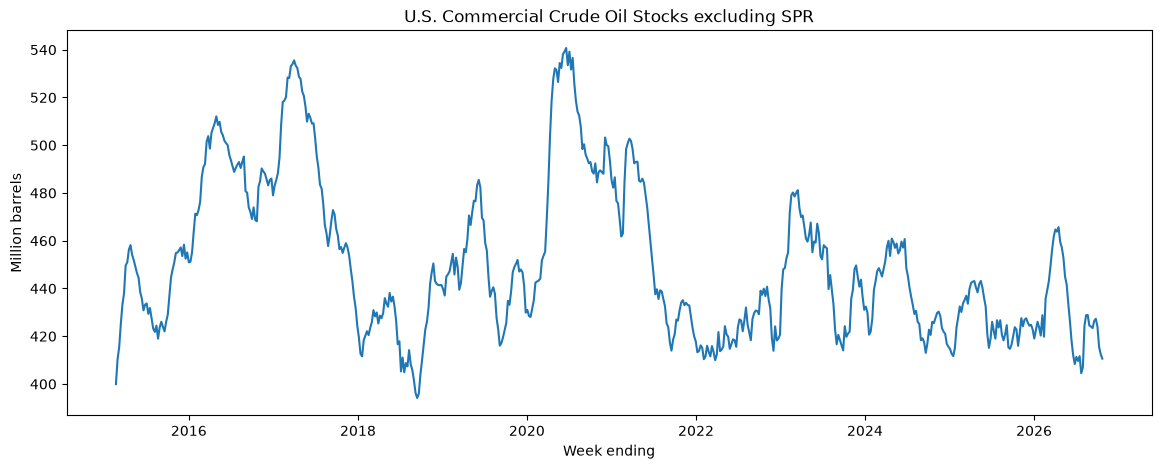

In [22]:
if "crude_stocks_mmbbl" in weekly_features.columns:
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        weekly_features["period"],
        weekly_features["crude_stocks_mmbbl"],
    )

    ax.set_title("U.S. Commercial Crude Oil Stocks excluding SPR")
    ax.set_xlabel("Week ending")
    ax.set_ylabel("Million barrels")

    plt.show()


## 18. Визуальная проверка ΔStocks и approximate balance

График нужен только как sanity check: смотрим, похожи ли направления и масштаб на части истории.


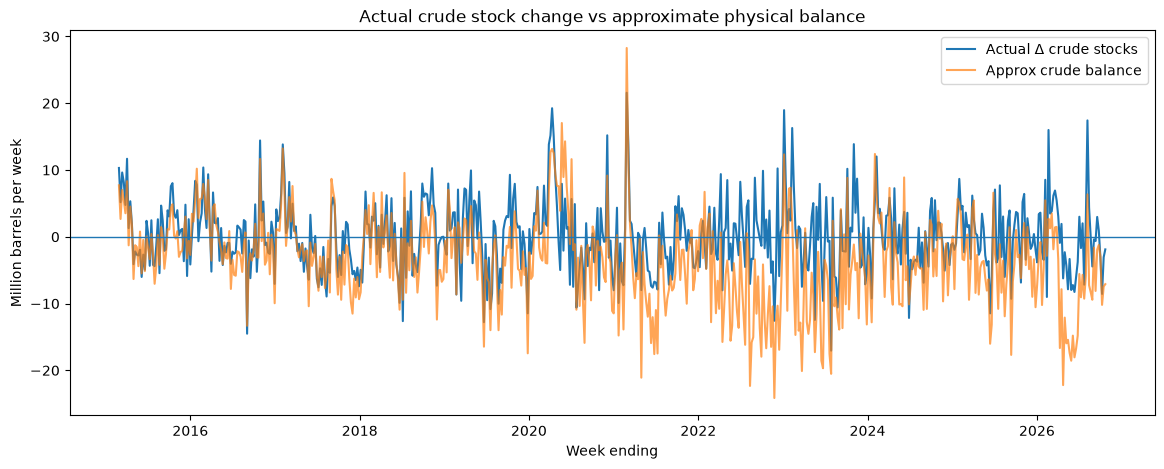

In [23]:
required_plot_cols = {
    "crude_stocks_change_mmbbl",
    "approx_crude_balance_mmbbl",
}

if required_plot_cols.issubset(weekly_features.columns):
    plot_df = weekly_features[
        [
            "period",
            "crude_stocks_change_mmbbl",
            "approx_crude_balance_mmbbl",
        ]
    ].dropna()

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        plot_df["period"],
        plot_df["crude_stocks_change_mmbbl"],
        label="Actual Δ crude stocks",
    )
    ax.plot(
        plot_df["period"],
        plot_df["approx_crude_balance_mmbbl"],
        label="Approx crude balance",
        alpha=0.7,
    )

    ax.axhline(0, linewidth=1)
    ax.set_title("Actual crude stock change vs approximate physical balance")
    ax.set_xlabel("Week ending")
    ax.set_ylabel("Million barrels per week")
    ax.legend()

    plt.show()


# 19. Исторические WTI futures F1–F4

EIA публиковала первые четыре последовательных NYMEX WTI futures:

- `RCLC1` → F1, ближайший контракт;
- `RCLC2` → F2;
- `RCLC3` → F3;
- `RCLC4` → F4.

Для стратегии используем форму кривой:

```text
Calendar Spread = F_near - F_far
```

При нашем соглашении:

- spread > 0 → backwardation;
- spread < 0 → contango.

История EIA для этих futures заканчивается в апреле 2024 года. Более поздний период будем отдельно дополнять теми же первыми четырьмя WTI CL contracts из Barchart или другого источника.


In [24]:
EIA_WTI_FUTURES_SERIES


{'wti_f1': {'route': 'petroleum/pri/fut',
  'series': 'RCLC1',
  'frequency': 'daily'},
 'wti_f2': {'route': 'petroleum/pri/fut',
  'series': 'RCLC2',
  'frequency': 'daily'},
 'wti_f3': {'route': 'petroleum/pri/fut',
  'series': 'RCLC3',
  'frequency': 'daily'},
 'wti_f4': {'route': 'petroleum/pri/fut',
  'series': 'RCLC4',
  'frequency': 'daily'}}

## 20. Sanity check WTI F1


In [25]:
test_f1 = client.fetch_series(
    route="petroleum/pri/fut",
    series="RCLC1",
    frequency="daily",
    start="2024-01-01",
    end="2024-04-30",
)

test_f1.tail()


,period,value,series,series_description,units,route,frequency
61,2024-04-01,83.71,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
62,2024-04-02,85.15,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
63,2024-04-03,85.43,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
64,2024-04-04,86.59,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily
65,2024-04-05,86.91,RCLC1,"Cushing, OK Crude Oil Future Contract 1 (Dolla...",$/BBL,petroleum/pri/fut,daily


In [26]:
print("F1 observations:", len(test_f1))

if not test_f1.empty:
    print("F1 period:", test_f1["period"].min(), "->", test_f1["period"].max())


F1 observations: 66
F1 period: 2024-01-02 00:00:00 -> 2024-04-05 00:00:00


## 21. Загружаем F1–F4


In [27]:
futures = client.fetch_many(
    series=EIA_WTI_FUTURES_SERIES,
    start=START_DATE,
    end=END_DATE,
)

futures.head()


INFO | Downloading wti_f1: petroleum/pri/fut | RCLC1 | daily
INFO | 2,305 observations | 2015-02-19 -> 2024-04-05
INFO | Downloading wti_f2: petroleum/pri/fut | RCLC2 | daily
INFO | 2,305 observations | 2015-02-19 -> 2024-04-05
INFO | Downloading wti_f3: petroleum/pri/fut | RCLC3 | daily
INFO | 2,305 observations | 2015-02-19 -> 2024-04-05
INFO | Downloading wti_f4: petroleum/pri/fut | RCLC4 | daily
INFO | 2,305 observations | 2015-02-19 -> 2024-04-05


,period,wti_f1,wti_f2,wti_f3,wti_f4
0,2015-02-19,51.16,51.83,53.00,54.22
1,2015-02-20,50.34,50.81,52.09,53.45
2,2015-02-23,49.45,51.01,52.56,54.06
3,2015-02-24,49.28,50.83,52.34,53.79
4,2015-02-25,50.99,52.76,54.31,55.77


In [28]:
print("Shape:", futures.shape)
print("Period:", futures["period"].min(), "->", futures["period"].max())

futures.tail(10)


Shape: (2305, 5)
Period: 2015-02-19 00:00:00 -> 2024-04-05 00:00:00


,period,wti_f1,wti_f2,wti_f3,wti_f4
2295,2024-03-22,80.63,80.17,79.61,78.95
2296,2024-03-25,81.95,81.38,80.77,80.06
2297,2024-03-26,81.62,81.04,80.43,79.73
2298,2024-03-27,81.35,80.78,80.19,79.52
2299,2024-03-28,83.17,82.42,81.67,80.89
2300,2024-04-01,83.71,82.82,81.98,81.12
2301,2024-04-02,85.15,84.22,83.29,82.34
2302,2024-04-03,85.43,84.61,83.77,82.88
2303,2024-04-04,86.59,85.81,84.96,84.03
2304,2024-04-05,86.91,86.10,85.20,84.24


# 22. Calendar spreads

Считаем:

```text
F1-F2
F1-F3
F1-F4
```

Основной кандидат для стратегии — `F1-F3`, но заранее не фиксируем победителя: позже сравним реакцию каждого spread на inventory surprise.


In [29]:
futures_features = futures.copy()

SPREAD_SPECS = [
    ("wti_f1", "wti_f2", "spread_1_2"),
    ("wti_f1", "wti_f3", "spread_1_3"),
    ("wti_f1", "wti_f4", "spread_1_4"),
]

for near_col, far_col, spread_col in SPREAD_SPECS:
    if {near_col, far_col}.issubset(futures_features.columns):
        futures_features[spread_col] = (
            futures_features[near_col]
            - futures_features[far_col]
        )

futures_features.tail()


,period,wti_f1,wti_f2,wti_f3,wti_f4,spread_1_2,spread_1_3,spread_1_4
2300,2024-04-01,83.71,82.82,81.98,81.12,0.89,1.73,2.59
2301,2024-04-02,85.15,84.22,83.29,82.34,0.93,1.86,2.81
2302,2024-04-03,85.43,84.61,83.77,82.88,0.82,1.66,2.55
2303,2024-04-04,86.59,85.81,84.96,84.03,0.78,1.63,2.56
2304,2024-04-05,86.91,86.10,85.20,84.24,0.81,1.71,2.67


## 23. Изменения calendar spread

Для event study нас интересует не только уровень кривой, но и её движение:

```text
ΔSpread_t = Spread_t - Spread_(t-1)
```

Позже вместо простого daily diff будем строить точное pre/post окно относительно `release_datetime`.


In [30]:
spread_columns = [
    col
    for col in [
        "spread_1_2",
        "spread_1_3",
        "spread_1_4",
    ]
    if col in futures_features.columns
]

for col in spread_columns:
    futures_features[f"delta_{col}"] = futures_features[col].diff()

futures_features.tail()


,period,wti_f1,wti_f2,wti_f3,wti_f4,spread_1_2,spread_1_3,spread_1_4,delta_spread_1_2,delta_spread_1_3,delta_spread_1_4
2300,2024-04-01,83.71,82.82,81.98,81.12,0.89,1.73,2.59,0.14,0.23,0.31
2301,2024-04-02,85.15,84.22,83.29,82.34,0.93,1.86,2.81,0.04,0.13,0.22
2302,2024-04-03,85.43,84.61,83.77,82.88,0.82,1.66,2.55,-0.11,-0.20,-0.26
2303,2024-04-04,86.59,85.81,84.96,84.03,0.78,1.63,2.56,-0.04,-0.03,0.01
2304,2024-04-05,86.91,86.10,85.20,84.24,0.81,1.71,2.67,0.03,0.08,0.11


## 24. Визуальная проверка F1-F3


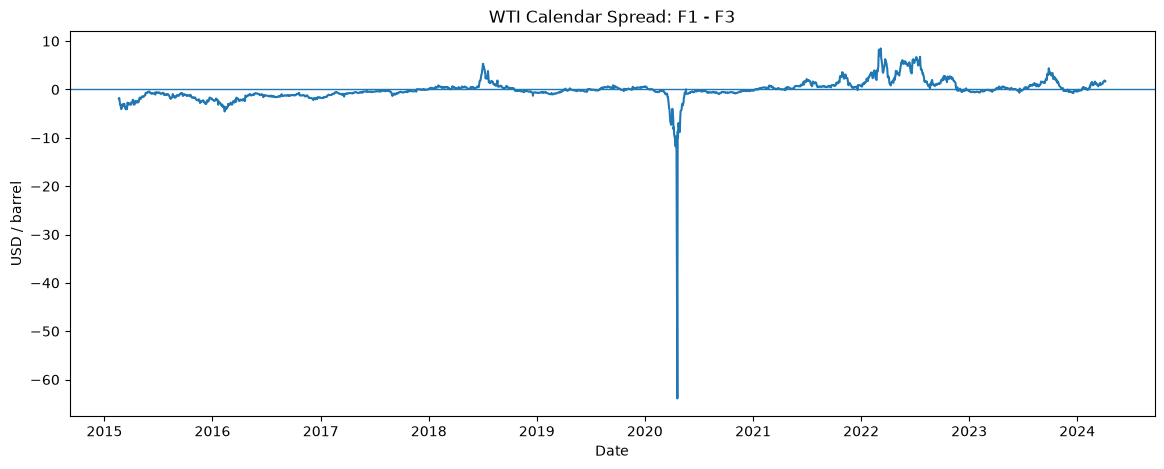

In [31]:
if "spread_1_3" in futures_features.columns:
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        futures_features["period"],
        futures_features["spread_1_3"],
    )

    ax.axhline(0, linewidth=1)
    ax.set_title("WTI Calendar Spread: F1 - F3")
    ax.set_xlabel("Date")
    ax.set_ylabel("USD / barrel")

    plt.show()


# 25. Общий контроль качества


In [32]:
def data_summary(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_pct": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(dropna=True),
        }
    )


data_summary(weekly_features)


,dtype,missing,missing_pct,n_unique
period,datetime64[us],0,0.00,610
crude_stocks,int64,0,0.00,609
cushing_stocks,int64,0,0.00,610
padd1_stocks,int64,0,0.00,593
padd2_stocks,int64,0,0.00,602
padd3_stocks,int64,0,0.00,609
padd4_stocks,int64,0,0.00,581
padd5_stocks,int64,0,0.00,596
crude_production,int64,0,0.00,290
crude_imports,int64,0,0.00,561


In [33]:
data_summary(futures_features)


,dtype,missing,missing_pct,n_unique
period,datetime64[us],0,0.00,2305
wti_f1,float64,0,0.00,1912
wti_f2,float64,0,0.00,1906
wti_f3,float64,0,0.00,1865
wti_f4,float64,0,0.00,1882
spread_1_2,float64,0,0.00,666
spread_1_3,float64,0,0.00,978
spread_1_4,float64,0,0.00,1151
delta_spread_1_2,float64,1,0.04,344
delta_spread_1_3,float64,1,0.04,470


# 26. Сохранение данных

Разделяем **raw** и **processed**:

### `data/raw/eia/`
Результат API практически без feature engineering.

### `data/processed/`
Производные признаки:

- MMbbl;
- stock changes;
- net imports;
- approximate crude balance;
- calendar spreads;
- Δspreads.

Эти каталоги обычно исключены из Git через `.gitignore`.


In [34]:
weekly_raw_csv = RAW_DIR / "eia_weekly_2015_2026.csv"
weekly_raw_parquet = RAW_DIR / "eia_weekly_2015_2026.parquet"
weekly_processed_parquet = PROCESSED_DIR / "eia_weekly_features.parquet"

weekly.to_csv(weekly_raw_csv, index=False)
weekly.to_parquet(weekly_raw_parquet, index=False)
weekly_features.to_parquet(weekly_processed_parquet, index=False)

print("Saved weekly files:")
print(weekly_raw_csv)
print(weekly_raw_parquet)
print(weekly_processed_parquet)


Saved weekly files:
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_weekly_2015_2026.csv
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_weekly_2015_2026.parquet
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/processed/eia/eia_weekly_features.parquet


In [35]:
futures_raw_csv = RAW_DIR / "eia_wti_futures_2015_2024.csv"
futures_raw_parquet = RAW_DIR / "eia_wti_futures_2015_2024.parquet"
futures_processed_parquet = (
    PROCESSED_DIR / "eia_wti_futures_features_2015_2024.parquet"
)

futures.to_csv(futures_raw_csv, index=False)
futures.to_parquet(futures_raw_parquet, index=False)
futures_features.to_parquet(futures_processed_parquet, index=False)

print("Saved futures files:")
print(futures_raw_csv)
print(futures_raw_parquet)
print(futures_processed_parquet)


Saved futures files:
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_wti_futures_2015_2024.csv
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/eia/eia_wti_futures_2015_2024.parquet
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/processed/eia/eia_wti_futures_features_2015_2024.parquet


# 27. Что собрано и что будет дальше

После выполнения ноутбука EIA-блок содержит:

### Физические stocks
- U.S. commercial crude excluding SPR;
- Cushing;
- PADD 1–5;
- gasoline;
- distillates;
- SPR.

### Физические flows
- crude production;
- imports;
- exports;
- refinery inputs;
- refinery utilization;
- products supplied.

### Производные фундаментальные признаки
- weekly stock changes;
- net crude imports;
- approximate crude balance.

### Рыночный блок
- WTI F1–F4;
- F1-F2;
- F1-F3;
- F1-F4;
- daily changes spreads.

---

## Что ещё не входит в EIA notebook

Следующие источники собираются отдельно:

1. **Consensus** — чтобы получить `Inventory Surprise`.
2. **Release calendar / release_datetime** — для point-in-time alignment и защиты от leakage.
3. **Barchart / другой источник WTI после 2024-04-05** — продолжение F1–F4.
4. **API Weekly Statistical Bulletin**, если решим использовать его как pre-EIA signal.
5. **News / Media Cloud** — события для news graph.

---

## Leakage warning

Текущие weekly fundamentals собраны как полная историческая таблица для анализа.

При обучении модели, которая делает прогноз **до выхода EIA WPSR**, нельзя напрямую использовать значения `production_t`, `imports_t`, `exports_t`, `refinery_inputs_t` и другие показатели, если они становятся известны одновременно с `stocks_t`.

В model-ready dataset такие признаки будут лагированы и выровнены по фактическому `release_datetime`.
